# Local: A3 and A4, the MLP-JEPA on the state (a laptop, no pod)

**Ablations, not model candidates** (README, "Ids"). The flat baseline B1's losses (prediction, SIGReg 0.09, one-step IDM 0.1, a latent of 192 behind a BatchNorm projector, clips of 4 frames) on an MLP encoder of the simulator's `state` column instead of the pixels: no ViT and no CLS token. **A3** trains it as B1 trains; **A4** detaches the prediction target (stop-gradient), so the prediction loss reaches the encoder only through the context. Both train one epoch of the training file (B1's first epoch) and read the latent at many steps from the untrained encoder on (`state_jepa.trace`): the mobs, ores, lava and the tiles of each type in view, the four tiles next to the player, the inventory, vitals and daylight (linear read on held-out episodes), the effective rank and the dead axes, the variance inside a clip, the predictor's error over copying.

The question (2026-11-02): does the encoder remove the variance the predictor cannot predict yet, before the predictor learns it, in the first epoch? How to read the report:

| A3 | A4 | reading |
|---|---|---|
| loses the mobs and ores (as B1) | keeps them | the target path removes them; B1 with stop-gradient on a pod is worth its time |
| loses them | loses them | not the target path: another force (SIGReg, IDM) or nothing that asks for them |
| keeps them | keeps them | the ViT and its CLS token are the more likely cause; a patch-token latent is the next test |

A loss in A3 is the strong result (the MLP reads every tile directly, an easier setting than the pixels); a kept factor is the weaker one. One seed. The `state` is simulator ground truth: the world models never see it.

| step | what |
|---|---|
| 0 | configuration, the Python with the requirements, the episode files linked into `data/local/` |
| 1 | **smoke run**: 30 steps on 20 episodes, a few seconds |
| 2 | **A3** (`experiments/run.py run A3`): about 7.5 minutes of training on an M1 Max (29 ms per step, 15.5k steps) plus the checks, then `reports/A3_trace.md` |
| 3 | **A4** (`run.py run A4`): the same with the stop-gradient, then the comparison with A3 (`reports/A4_trace.md`) |
| 4 | the report and the figure |
| 5 | the reports and the traces into the repository (`reports/A3_A4/`) |

Open this notebook from `notebooks/` of the clone. The kernel only starts commands: `PYTHON` must have the H-JEPA requirements (`environment/hjepa-requirements.txt`, the CPU torch of its header). A finished run is skipped when its cell runs again (`run.py` sees `model.pt`); `--force` in the start cell repeats it.

In [4]:
# --- 0. Configuration ------------------------------------------------------------------------------------------------
import os, shutil, subprocess, sys
from pathlib import Path

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()   # the clone (this notebook is opened from notebooks/)
FILES = REPO / "data" / "hf" / "craftax-classic-pqn-rnn-v1" / "data"   # the episode files from the Hub repo of runpod_dataset.ipynb (data/)
HOME = REPO / "data" / "local"             # HJEPA_HOME of these runs: links to the files, the runs (ckpts/craftax/A3, A4), the reports; data/ is gitignored
PYTHON = sys.executable                    # a Python with the H-JEPA requirements; the path of a venv's python if the kernel has none
SEEDS = "42"                               # one seed, as for every variant
THREADS = 8 
PYTHON = str(REPO / ".venv" / "bin" / "python")   # the venv of the workspace (.venv links to ~/venvs/aac-hjepa)
                               # torch threads (OMP_NUM_THREADS): 8 of the 10 cores of an M1 Max

In [8]:
# --- 0. The environment of the commands, the requirements, the episode files ----------------------------------------------
H_JEPA = REPO / "H-JEPA" / "h_jepa"
RUNNER = [PYTHON, REPO / "experiments" / "run.py"]
ENV = {**os.environ, "PATH": f"{Path(PYTHON).parent}:{os.environ['PATH']}",   # `python` in run.py's commands is this venv's
       "HJEPA_HOME": str(HOME), "PYTHONPATH": f"{H_JEPA.parent}:{H_JEPA}", "OMP_NUM_THREADS": str(THREADS),
       "MKL_NUM_THREADS": str(THREADS), "MPLBACKEND": "agg", "PYTHONUNBUFFERED": "1"}


def sh(cmd, cwd=None):
    """Run a command and stream its output into the cell (without the packages' import logs); stop on a failure."""
    cmd = [str(c) for c in cmd]
    print("$", " ".join(cmd))
    proc = subprocess.Popen(cmd, cwd=cwd, env=ENV, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in proc.stdout:
        if " | INFO  | " not in line:
            print(line, end="")
    if proc.wait():
        raise RuntimeError(f"{cmd[1]} failed with exit code {proc.returncode}")


out = subprocess.run([PYTHON, "-c", "import torch, h5py, yaml, matplotlib, omegaconf; print(torch.__version__)"], capture_output=True, text=True)
assert out.returncode == 0, f"{PYTHON} lacks the H-JEPA requirements: {out.stderr.strip().splitlines()[-1:]}"
print("torch", out.stdout.strip(), "in", PYTHON)
HOME.mkdir(parents=True, exist_ok=True)
CHECK = "import h5py, sys; f = h5py.File(sys.argv[1], 'r'); print('relabel' in f.attrs and 'action_policy' in f, f['state'].shape[1])"
for split in ("train", "val"):
    src, dst = FILES / f"craftax_expert_{split}.h5", HOME / f"craftax_expert_{split}.h5"
    assert src.exists(), f"missing {src}: download data/ of the Hub repo (runpod_dataset.ipynb filled it)"
    if not dst.exists():
        dst.symlink_to(src)
    # the executed actions (relabel_dataset.ipynb) and the state column of 1345 floats
    relabeled, width = subprocess.run([PYTHON, "-c", CHECK, dst], capture_output=True, text=True).stdout.split()
    assert relabeled == "True" and width == "1345", f"{src}: relabeled {relabeled}, state width {width}"
    print(f"{split}: {dst} -> {src}")

torch 2.7.1 in /Users/julian.quast/Documents/Kailash/AAC/.venv/bin/python
train: /Users/julian.quast/Documents/Kailash/AAC/data/local/craftax_expert_train.h5 -> /Users/julian.quast/Documents/Kailash/AAC/data/hf/craftax-classic-pqn-rnn-v1/data/craftax_expert_train.h5
val: /Users/julian.quast/Documents/Kailash/AAC/data/local/craftax_expert_val.h5 -> /Users/julian.quast/Documents/Kailash/AAC/data/hf/craftax-classic-pqn-rnn-v1/data/craftax_expert_val.h5


## 1. Smoke run

The real command on the real files, 30 steps on the first 20 training episodes, the latent read at steps 0, 10, 20 and 30 on 12 held-out episodes: it proves the columns, the paths and the outputs before the runs. The numbers of a smoke run mean nothing.

In [6]:
# --- 1. Smoke run on the real files --------------------------------------------------------------------------------------------
SMOKE = HOME / "ckpts" / "craftax" / "A3_smoke" / f"seed{SEEDS.split(',')[0]}"
shutil.rmtree(SMOKE, ignore_errors=True)
sh([PYTHON, "-m", "state_jepa.train", "--train-file", HOME / "craftax_expert_train.h5", "--val-file", HOME / "craftax_expert_val.h5",
    "--out", SMOKE, "--max-steps", 30, "--max-episodes", 20, "--max-val-episodes", 12, "--check-every", 10, "--log-every", 10], cwd=H_JEPA)
assert (SMOKE / "trace.json").exists() and (SMOKE / "model.pt").exists(), "the smoke run wrote no trace or model"

$ /Users/julian.quast/Documents/Kailash/AAC/.venv/bin/python -m state_jepa.train --train-file /Users/julian.quast/Documents/Kailash/AAC/data/local/craftax_expert_train.h5 --val-file /Users/julian.quast/Documents/Kailash/AAC/data/local/craftax_expert_val.h5 --out /Users/julian.quast/Documents/Kailash/AAC/data/local/ckpts/craftax/A3_smoke/seed42 --max-steps 30 --max-episodes 20 --max-val-episodes 12 --check-every 10 --log-every 10
[state_jepa] 16542 training frames, 16482 clips (128 steps per epoch), 30 steps; 12 held-out episodes in the sample; 3 s
[state_jepa] step 0/30 (0 s): rank 41, dead 76, near 0.61, cow -0.53 zombie -0.02 iron 0.09 coal 0.03, pred/copy 61.01
[state_jepa] step 10/30 (1 s): rank 36, dead 94, near 0.63, cow -0.44 zombie 0.01 iron 0.12 coal 0.03, pred/copy 8.13
[state_jepa] step 20/30 (1 s): rank 26, dead 107, near 0.62, cow -0.58 zombie 0.03 iron 0.12 coal 0.02, pred/copy 3.82
[state_jepa] step 30/30 (2 s): rank 24, dead 110, near 0.62, cow -0.58 zombie 0.02 iron 0.

## 2. A3: B1's losses on the state

`run.py run A3`: one epoch, the latent read at steps 0, 50, 100, 200, 300, 500, 750, 1000, 1500, 2000 and then every 1000 (`state_jepa.train.CHECKS`); the progress lines show the rank, the dead axes, the near field, cow, zombie, iron and coal, and the predictor against copying at each check. Then `reports/A3_trace.md`.

In [9]:
# --- 2. A3 ---------------------------------------------------------------------------------------------------------------------
sh([*RUNNER, "plan", "A3", "--seeds", SEEDS])
sh([*RUNNER, "run", "A3", "--mode", "local", "--seeds", SEEDS])

$ /Users/julian.quast/Documents/Kailash/AAC/.venv/bin/python /Users/julian.quast/Documents/Kailash/AAC/experiments/run.py plan A3 --seeds 42
[train] train_A3_s42
    cd H-JEPA/h_jepa && python -m state_jepa.train --train-file /Users/julian.quast/Documents/Kailash/AAC/data/local/craftax_expert_train.h5 --val-file /Users/julian.quast/Documents/Kailash/AAC/data/local/craftax_expert_val.h5 --out /Users/julian.quast/Documents/Kailash/AAC/data/local/ckpts/craftax/A3/seed42 --seed 42 --epochs 1
[compare] compare_A3_trace  after train_A3_s42
    cd H-JEPA/h_jepa && python -m state_jepa.report --out /Users/julian.quast/Documents/Kailash/AAC/data/local/reports/A3_trace.md A3_s42=/Users/julian.quast/Documents/Kailash/AAC/data/local/ckpts/craftax/A3/seed42
$ /Users/julian.quast/Documents/Kailash/AAC/.venv/bin/python /Users/julian.quast/Documents/Kailash/AAC/experiments/run.py run A3 --mode local --seeds 42
run  train_A3_s42: python -m state_jepa.train --train-file /Users/julian.quast/Documents/Kai

## 3. A4: the same with the stop-gradient, against A3

`run.py run A4`: A3's settings and one change (`--stop-grad`), then the report of both runs side by side (`reports/A4_trace.md` and its figure). A3 must have run first: it is A4's reference.

In [10]:
# --- 3. A4 and the comparison with A3 -------------------------------------------------------------------------------------------
sh([*RUNNER, "plan", "A4", "--seeds", SEEDS])
sh([*RUNNER, "run", "A4", "--mode", "local", "--seeds", SEEDS])

$ /Users/julian.quast/Documents/Kailash/AAC/.venv/bin/python /Users/julian.quast/Documents/Kailash/AAC/experiments/run.py plan A4 --seeds 42
[train] train_A4_s42
    cd H-JEPA/h_jepa && python -m state_jepa.train --train-file /Users/julian.quast/Documents/Kailash/AAC/data/local/craftax_expert_train.h5 --val-file /Users/julian.quast/Documents/Kailash/AAC/data/local/craftax_expert_val.h5 --out /Users/julian.quast/Documents/Kailash/AAC/data/local/ckpts/craftax/A4/seed42 --seed 42 --epochs 1 --stop-grad
[compare] compare_A4_trace  after train_A4_s42
    cd H-JEPA/h_jepa && python -m state_jepa.report --out /Users/julian.quast/Documents/Kailash/AAC/data/local/reports/A4_trace.md A3_s42=/Users/julian.quast/Documents/Kailash/AAC/data/local/ckpts/craftax/A3/seed42 A4_s42=/Users/julian.quast/Documents/Kailash/AAC/data/local/ckpts/craftax/A4/seed42
$ /Users/julian.quast/Documents/Kailash/AAC/.venv/bin/python /Users/julian.quast/Documents/Kailash/AAC/experiments/run.py run A4 --mode local --seeds

## 4. The report

The table has selected steps and the last one per run, the figure every check on a log scale of the steps (the first point is the untrained encoder). Set the numbers next to B1's (its latent after 10 epochs: cow 0.03, iron 0.03, coal 0.14 as counts in view; `reports/slowness_F1/`) and read them with the table at the top of this notebook.

# MLP-JEPA on the state: what the latent holds over the training

Linear read (ridge, held-out episodes) of the latent at each check; `near`: the four tiles next to the player; `rank`: effective rank; `dead_axes`: principal axes under a tenth of the mean variance; `clip_share`: the variance inside a clip of 4 frames; `pred_over_copy`: the one-step error over copying the last latent. Step 0 is the untrained encoder.

- **A3_s42**: stop-grad False, latent 192, history 3, SIGReg 0.09, IDM 0.1, lr 0.001, 15551 steps (1.00 epochs), 24 checks
- **A4_s42**: stop-grad True, latent 192, history 3, SIGReg 0.09, IDM 0.1, lr 0.001, 15551 steps (1.00 epochs), 24 checks

| run | step | mob:cow | mob:zombie | mob:skeleton | mob:arrow | view:iron | view:coal | view:diamond | view:lava | view:grass | vital:food | inv:wood | daylight | near | rank | dead_axes | clip_share | pred_over_copy |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| A3_s42 | 0 | 0.13 | 0.14 | 0.07 | 0.05 | 0.04 | 0.20 | -0.04 | 0.43 | 0.99 | 0.50 | 0.17 | 0.59 | 0.71 | 51 | 58 | 0.16 | 54 |
| A3_s42 | 100 | 0.10 | 0.16 | 0.08 | 0.05 | 0.09 | 0.21 | -0.05 | 0.37 | 0.98 | 0.54 | 0.23 | 0.65 | 0.68 | 17 | 151 | 0.06 | 1.60 |
| A3_s42 | 500 | 0.09 | 0.19 | 0.08 | 0.06 | 0.11 | 0.24 | 0.03 | 0.45 | 0.97 | 0.49 | 0.20 | 0.74 | 0.60 | 21 | 170 | 0.06 | 0.57 |
| A3_s42 | 1000 | 0.07 | 0.18 | 0.07 | 0.05 | 0.11 | 0.26 | 0.02 | 0.42 | 0.96 | 0.49 | 0.28 | 0.86 | 0.58 | 22 | 169 | 0.07 | 0.36 |
| A3_s42 | 2000 | 0.06 | 0.18 | 0.06 | 0.05 | 0.12 | 0.23 | 0.02 | 0.39 | 0.95 | 0.39 | 0.39 | 0.87 | 0.55 | 23 | 168 | 0.07 | 0.27 |
| A3_s42 | 15551 | 0.05 | 0.23 | 0.09 | 0.06 | 0.11 | 0.22 | 0.02 | 0.44 | 0.98 | 0.36 | 0.72 | 0.93 | 0.55 | 34 | 155 | 0.07 | 0.13 |
| A4_s42 | 0 | 0.13 | 0.14 | 0.07 | 0.05 | 0.04 | 0.20 | -0.04 | 0.43 | 0.99 | 0.50 | 0.17 | 0.59 | 0.71 | 51 | 58 | 0.16 | 54 |
| A4_s42 | 100 | 0.14 | 0.15 | 0.05 | 0.02 | 0.09 | 0.20 | -0.05 | 0.57 | 0.97 | 0.55 | 0.19 | 0.77 | 0.73 | 53 | 92 | 0.16 | 1.56 |
| A4_s42 | 500 | 0.14 | 0.19 | 0.06 | 0.02 | 0.09 | 0.19 | -0.07 | 0.85 | 0.97 | 0.70 | 0.43 | 0.94 | 0.71 | 57 | 120 | 0.14 | 0.87 |
| A4_s42 | 1000 | 0.14 | 0.38 | 0.08 | 0.02 | 0.12 | 0.16 | -0.03 | 0.88 | 0.97 | 0.81 | 0.54 | 0.93 | 0.69 | 66 | 114 | 0.14 | 0.74 |
| A4_s42 | 2000 | 0.15 | 0.53 | 0.08 | 0.02 | 0.11 | 0.21 | -0.02 | 0.85 | 0.96 | 0.90 | 0.71 | 0.93 | 0.65 | 77 | 104 | 0.15 | 0.59 |
| A4_s42 | 15551 | 0.29 | 0.63 | 0.16 | 0.08 | 0.20 | 0.61 | -0.01 | 0.86 | 0.99 | 0.91 | 0.94 | 0.96 | 0.69 | 119 | 65 | 0.16 | 0.32 |

![A4_trace.png](A4_trace.png)


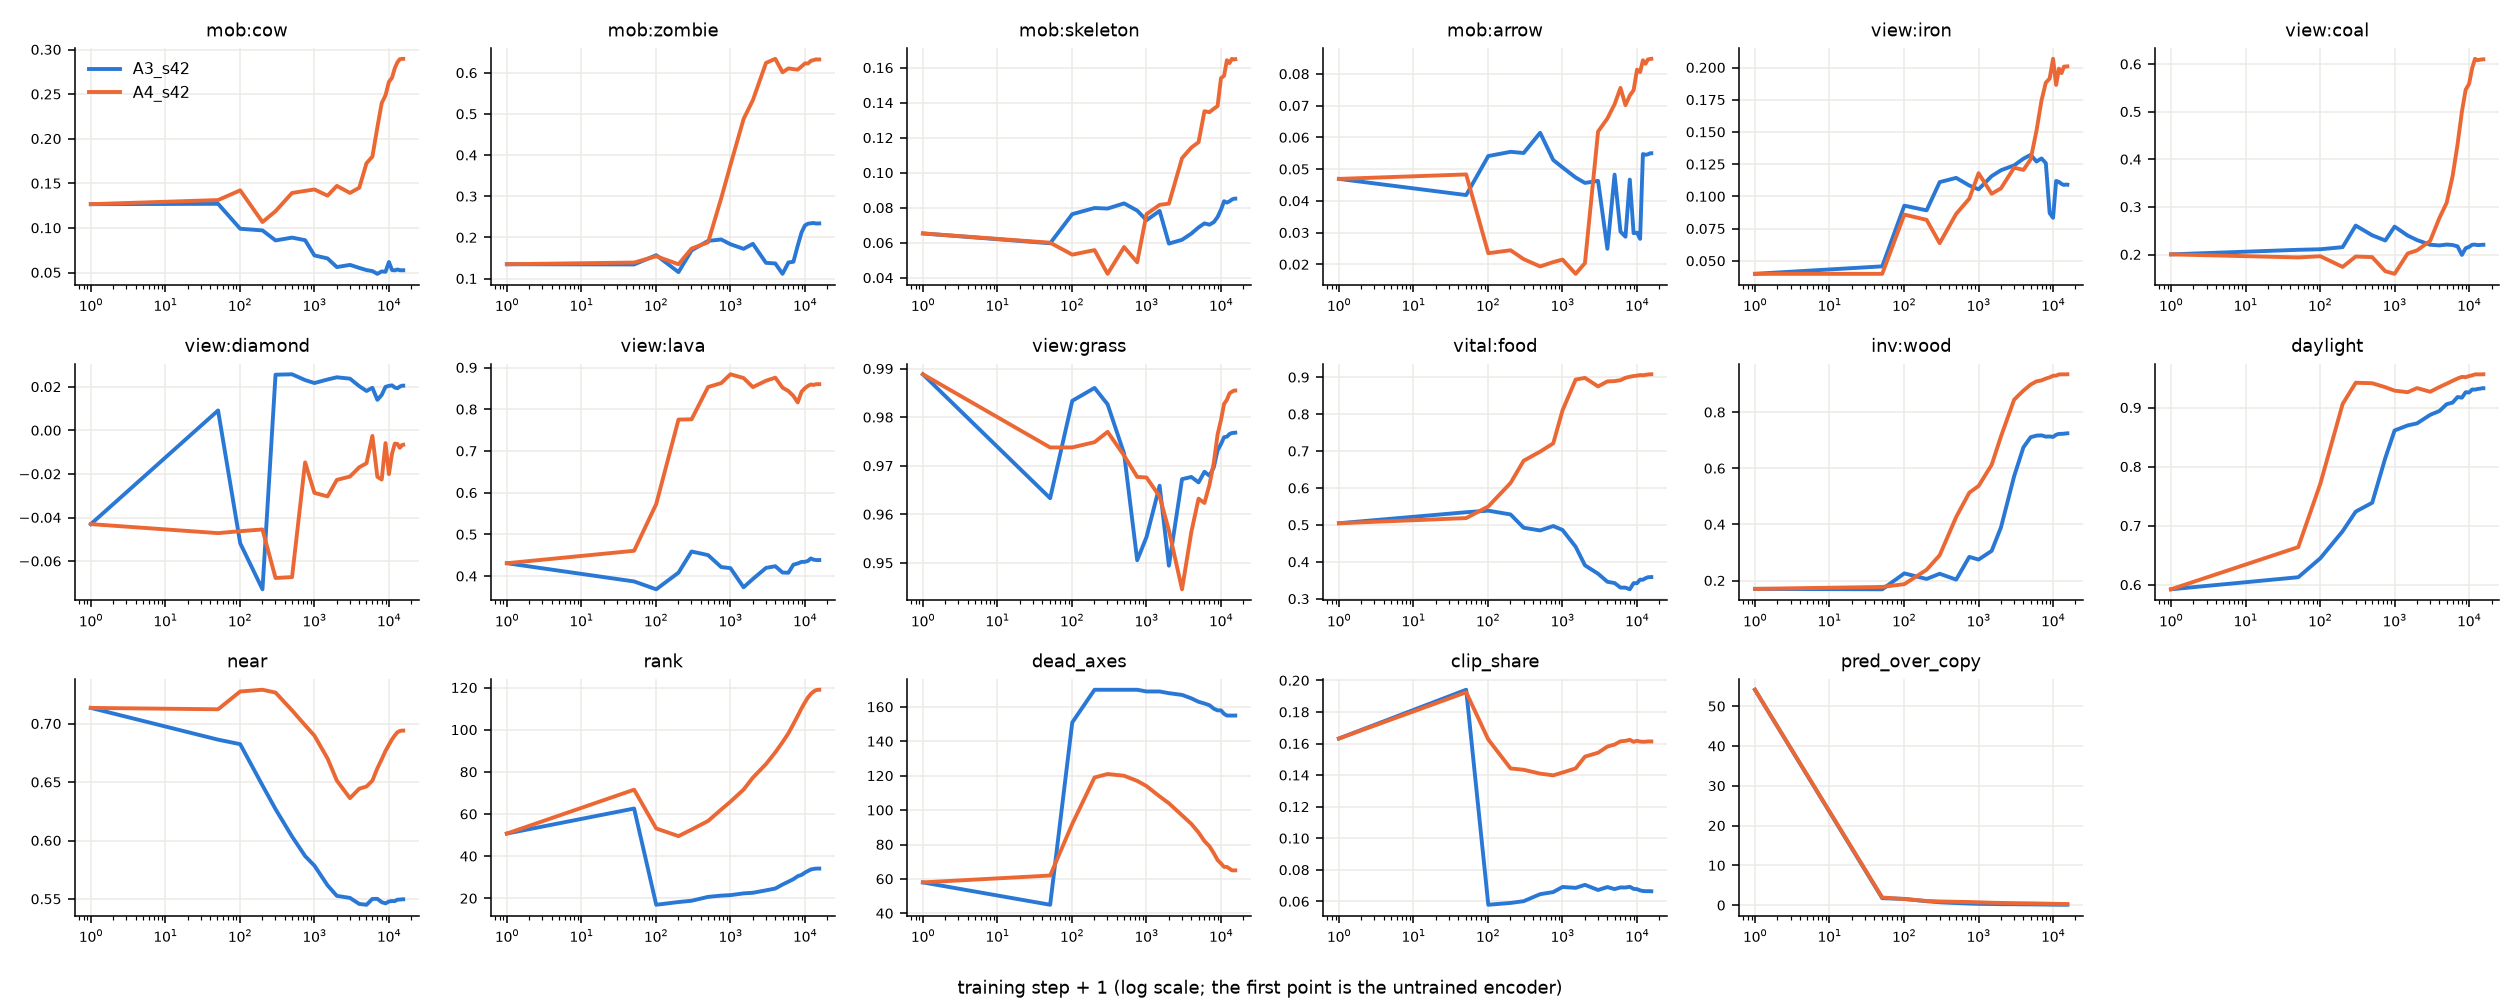

In [11]:
# --- 4. The report and the figure -------------------------------------------------------------------------------------------------
from IPython.display import Image, Markdown, display

report = HOME / "reports" / "A4_trace.md"
display(Markdown(report.read_text()))
display(Image(filename=str(report.with_suffix(".png"))))

## 5. Into the repository

The reports and the traces (readouts, losses, settings) go to `reports/A3_A4/` of the clone, to be committed; the models stay in `data/local/` (gitignored).

In [12]:
# --- 5. The reports and the traces into reports/A3_A4/ ---------------------------------------------------------------------------
KEEP = REPO / "reports" / "A3_A4"
KEEP.mkdir(parents=True, exist_ok=True)
for name in ("A3_trace.md", "A3_trace.png", "A4_trace.md", "A4_trace.png"):
    shutil.copy(HOME / "reports" / name, KEEP / name)
for run in ("A3", "A4"):
    (KEEP / run).mkdir(exist_ok=True)
    for name in ("trace.json", "config.json", "losses.csv"):
        shutil.copy(HOME / "ckpts" / "craftax" / run / f"seed{SEEDS.split(',')[0]}" / name, KEEP / run / name)
print("copied to", KEEP)

copied to /Users/julian.quast/Documents/Kailash/AAC/reports/A3_A4
